In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import tifffile
import fastplotlib as fpl

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
%matplotlib inline

In [ ]:
path = "/home/kushal/lab/datasets/jason/M19/D05/M19D5_MC.tif"
movie = tifffile.imread(path)[:10_000, 128:-138:2, 138:-132:2].astype(np.float32)

In [ ]:
movie_mean = movie.mean(axis=0)

In [ ]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

In [ ]:
iw_movie.window_funcs = {"t": (np.mean, 33)}

In [3]:
v1 = np.load("./v_ss-2.npy")

In [4]:
N_ROWS, N_COLS = 123, 121
n_pixels = N_ROWS * N_COLS
B = v1[0].reshape(n_pixels, n_pixels)
B = np.abs((B + B.T) / 2)

B.shape

(14883, 14883)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='900px', css_width='900px')
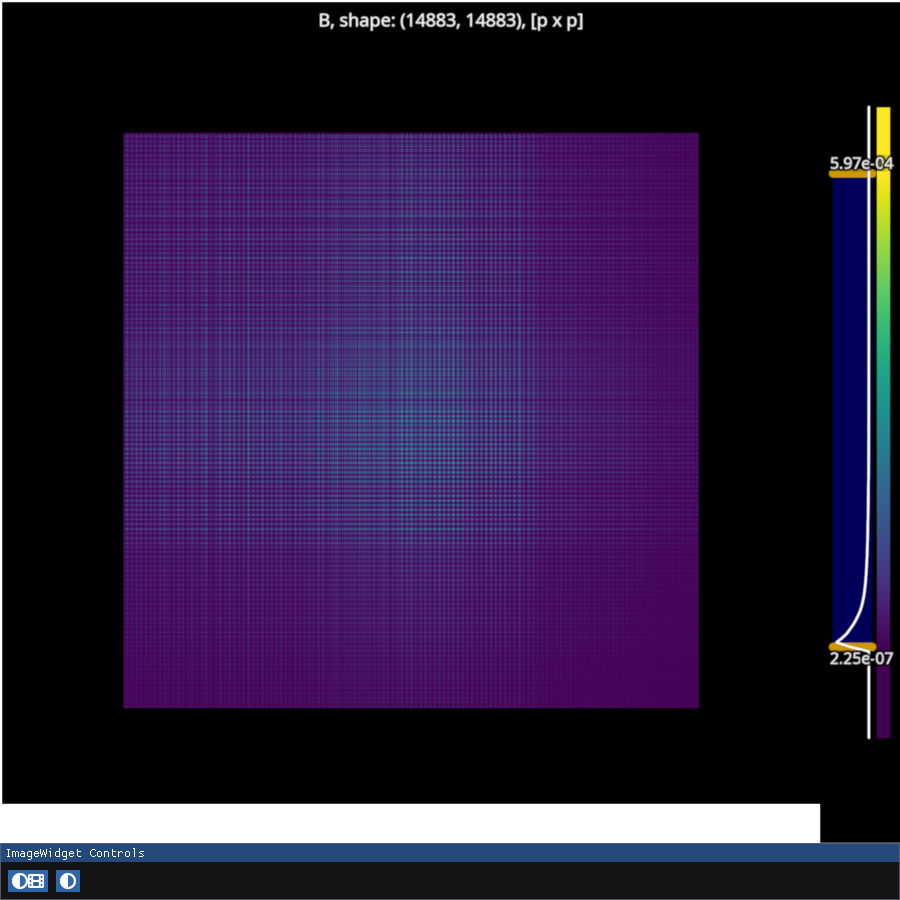

In [5]:
iw_adj = fpl.ImageWidget(
    B, 
    cmap="viridis",
    names=[f"B, shape: {B.shape}, [p x p]"],
    figure_kwargs={"size": (900, 900)},
)
iw_adj.show()

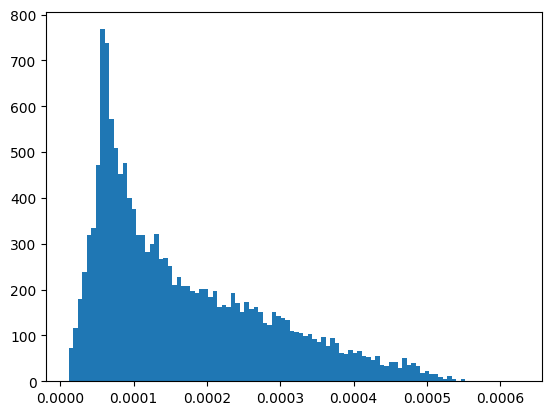

In [6]:
plt.hist(B.max(axis=1), bins=100)
plt.show()

# Determine columns/rowns which are just noise and exclude them

In [7]:
np.argsort(B.sum(axis=0))

array([14766, 14767, 14768, ...,  8792,  8192,  8794])

In [8]:
np.sum(B[14766, :])

np.float64(0.04641665180489722)

In [9]:
np.sum(B[8794, :])

np.float64(2.5013944978859315)

### background image, each pixel's value in the `bg_image` is the sum of that pixel's row/column from `B`

RFBOutputContext()

JupyterWgpuCanvas(css_height='700px', css_width='700px')
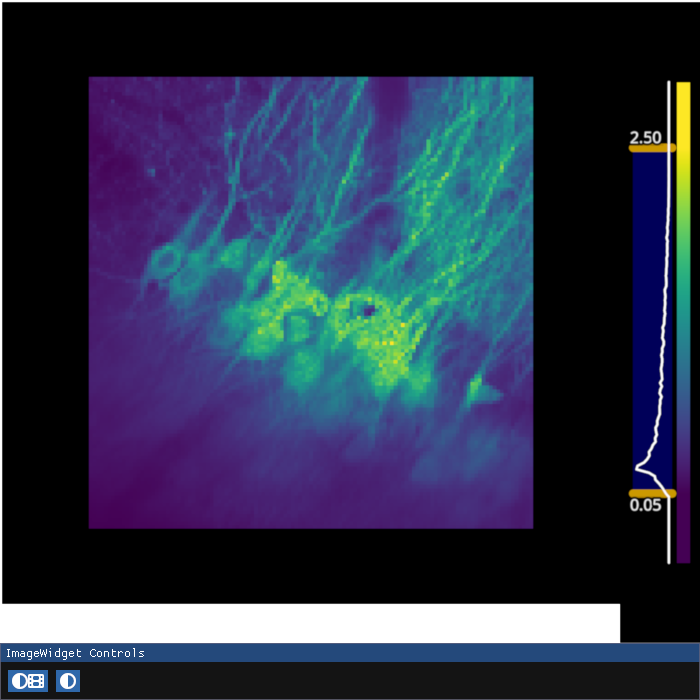

In [10]:
bg_image = B.sum(axis=0).reshape(N_ROWS, N_COLS)
iw_bg = fpl.ImageWidget(bg_image, cmap="viridis", figure_kwargs={"size": (700, 700)})
iw_bg.show()

## bg threshold

In [11]:
bg_threshold = 0.6
iw_bg.managed_graphics[0].vmin = 0.6

In [12]:
bg_ixs = B.sum(axis=0) < bg_threshold
bg_ixs

array([ True,  True,  True, ...,  True,  True,  True])

Used for mapping indices after bg removal back to original pixels in the image

In [13]:
NEW_IXS = np.where(B.sum(axis=0) > bg_threshold)[0]
NEW_IXS

array([   40,    51,    53, ..., 13051, 13052, 13171])

Number of bg pixels

In [14]:
np.count_nonzero(bg_ixs)

8215

# `B` without the bg rows and cols

In [15]:
B2 = B[~bg_ixs][:, ~bg_ixs]
B2.shape

(6668, 6668)

In [16]:
B2 = np.abs(B2 + B2.T) / 2

In [17]:
np.linalg.norm(B2 - B2.T, ord="fro")

np.float64(0.0)

## Eigendecomposition 

In [18]:
K_eig = 30

In [19]:
evals, Qk = scipy.sparse.linalg.eigsh(B2, k=K_eig)

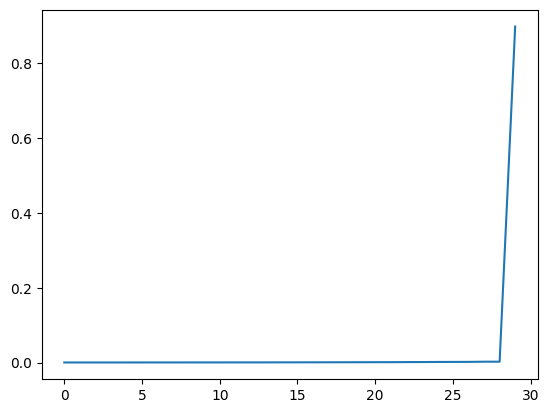

In [20]:
plt.plot(evals)

In [21]:
Qk.shape

(6668, 30)

In [22]:
Qk = Qk[:, ::-1]
evals = evals[::-1]

In [23]:
Qk.T[:] /= np.linalg.norm(Qk.T, axis=0, ord=2)

In [24]:
K_interp = 30

In [25]:
seed_ixs, proj = scipy.linalg.interpolative.interp_decomp(Qk.T[:K_interp], eps_or_k=K_interp)

In [26]:
seed_ixs

array([4454, 5693, 4640, ..., 6665, 6666, 6667], dtype=int32)

In [27]:
def coors_from_indices(indices: np.ndarray[int], k) -> np.ndarray:
    """get (x, y) image coordinates from the top `k` given flat pixel `indices`"""
    _ixs = NEW_IXS[indices[:k]]
    ys = np.floor_divide(_ixs, N_ROWS)
    xs = np.mod(_ixs, N_COLS)
    return np.column_stack([xs, ys])

In [28]:
seed_coors = coors_from_indices(seed_ixs, k=K_interp)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
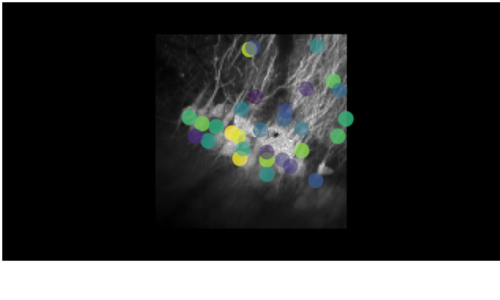

In [29]:
fig_seeds = fpl.Figure()

fig_seeds[0, 0].add_image(bg_image, cmap="gray")
fig_seeds[0, 0].add_scatter(seed_coors, sizes=15, cmap="viridis_r", alpha=0.7)

fig_seeds.show()

In [30]:
fig_seeds[0, 0].graphics[1].colors[:, -1] = 0.6

In [31]:
proj.shape

(30, 6638)

In [32]:
%matplotlib inline

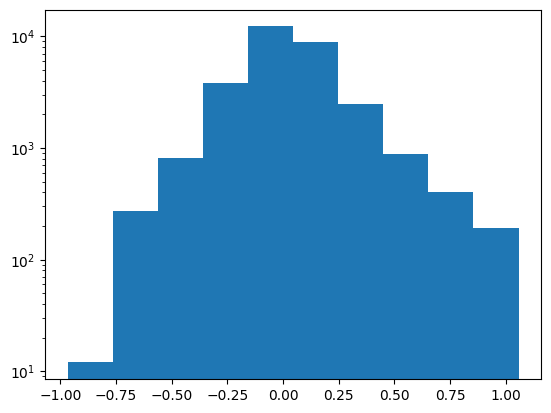

In [33]:
plt.hist(proj[:, :1000].ravel())
plt.semilogy()
plt.show()

In [34]:
def basis_vect_swap(a, idx, c, w, ind_old, ind_new):
    """
    given the interpolative decomposition A = C * W,
    we swap the basis vector (column of C) that is column ind_old
    of A with the basis vector that is column ind_new of A.

    NB: this code is inefficient and can be optimized in many ways.

    Parameters
    ----------
    a: k x n numpy array
        matrix of which we have the interpolative decomposition
    idx: array of length k
        indices of the k basis vectors
    c: k x k numpy array
        matrix of basis vectors (column-wise)
    w: k x n numpy array
        interpolation matrix
    ind_old: int
        the index of the basis vector to be replaced
    ind_new: int
        the index of the new basis vector

    Returns
    -------
    cnew: k x k numpy array
        new matrix of basis vectors
    wnew: k x n numpy array
        new interpolation matrix
    idx_new: array of length k
        new indices of basis vectors

    """
    k = c.shape[1]

    # choose some basis vector to replace
    v_old = a[:, ind_old]
    # its the interpolation matrix
    c_ind_old = np.where(idx == ind_old)[0][0]

    # choose new basis vector
    v_old = a[:, ind_old]
    v_new = a[:, ind_new]

    # construct new c (matrix with basis columns)
    cnew = c.copy()
    cnew[:, c_ind_old] = v_new

    # and new w
    wnew = np.linalg.inv(cnew) @ c  @ w

    idx_new = idx.copy()
    idx_new[c_ind_old] = ind_new

    # and check accuracy
    if not np.allclose(a, cnew @ wnew):
        raise ValueError

    return cnew, wnew, idx_new

In [35]:
k = K_eig
ixs = seed_ixs

C = Qk.T[:k][:, ixs[:k]].copy()
C_ixs = ixs[:k].copy()

W = np.hstack([np.eye(k), proj])[:, np.argsort(ixs)].copy()

In [36]:
from ipywidgets import HBox, VBox

In [37]:
iw_W = fpl.ImageWidget(W, cmap="seismic", figure_kwargs={"size": (1000, 1000)})
iw_W.managed_graphics[0].vmin = -1
iw_W.managed_graphics[0].vmax = 1
iw_W.figure[0, 0].camera.maintain_aspect = False

RFBOutputContext()

In [38]:
fig_nn = fpl.Figure()

fig_nn[0, 0].add_line(np.zeros((2, 3)))

RFBOutputContext()

LineGraphic @ 0x7ff51c6fec50

In [42]:
def get_bases_to_swap(W_, C_ixs_, negs_exclude_ix: list[int] = None) -> tuple[int, int]:
    """
    returns: old_ix, new_ix
    """
    # choose a random basis
    basis_old = np.random.choice(C_ixs_, size=1).item()

    negs = np.argwhere(W_ < -0.20)[:, 1]
    
    # exclude an index that has already been tried before
    for i in negs_exclude_ix:
        negs = negs[negs != i]
        
    negs_in_C_ixs = np.intersect1d(negs, C_ixs_, return_indices=True)[1]

    mask = np.ones(len(negs), bool)
    mask[negs_in_C_ixs] = False
    
    negs = negs[mask]
    
    # choose random column with negative to be new basis
    basis_new = np.random.choice(negs, size=1).item()

    return basis_old, basis_new

In [43]:
Ws = list()
n_nonneg = [(W < -0.25).sum()]
basis_flips = {
    "old": list(),
    "new": list()
}
max_iters = 100_000

C_ = C.copy()
W_ = W.copy()
C_ixs_ = C_ixs.copy()

negs_exclude_iter = list()

n_iter = 0

In [52]:
for i in tqdm(range(max_iters)):
    basis_old, basis_new = get_bases_to_swap(W_, C_ixs_, list())
    
    C2, W2, C_ixs2 = basis_vect_swap(Qk.T[:k], C_ixs_, C_, W_, basis_old, basis_new)
    
    # check if W2 is more non-negative than W_
    n_nn = (W2 < -0.25).sum()
    if n_nn < n_nonneg[-1]:
        W_ = W2
        C_ = C2
        C_ixs_ = C_ixs2
        Ws.append(W_)
        n_nonneg.append(n_nn)
        basis_flips["old"].append(basis_old)
        basis_flips["new"].append(basis_new)
        negs_exclude_iter.clear()
    
    else:
        # pick different columns, exclude one we already tried
        negs_exclude_iter.append(basis_new)
        basis_old, basis_new = get_bases_to_swap(W_, C_ixs_, negs_exclude_ix=negs_exclude_iter)
    # no more non-negative element, we're done :D !!
    if n_nn < 1:
        break

100%|█████████████████████████████████████████████████████████████████| 100000/100000 [44:32<00:00, 37.42it/s]


# reconstruct images from proj

In [46]:
def images_from_proj(projection, new_indices, projection_indices):
    """
    reconstruct images that represent each cluster from the interpolative decomposition projection

    Parameters
    ----------
    projection: np.ndarray
        projection
        
    k: int
        number of seeds that exist, this MUST hold: (k + projection.shape[1] = Qk.shape[0])

    new_indices: np.ndarray[int]
        indices that map from smaller-B matrix after thresholding to actual pixel indices in the original big B matrix

    projection_indices: np.ndarray[int]
        indices returned from interp decomp
    """
    k = projection.shape[0]
    
    images = np.zeros((k, N_ROWS * N_COLS))

    indices = new_indices[projection_indices]

    for i in range(k):
        images[i, indices] = projection[i]

    return images.reshape((k, N_ROWS, N_COLS))

In [53]:
imgs = images_from_proj(W_, NEW_IXS, seed_ixs)

In [54]:
imgs.shape

(30, 123, 121)

In [55]:
iw_W.managed_graphics[0].data = W_

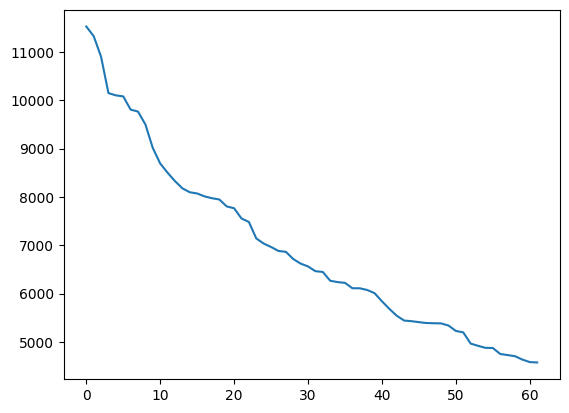

In [56]:
plt.plot(n_nonneg)

In [57]:
iw_proj = fpl.ImageWidget([img for img in imgs], cmap="seismic")
for g in iw_proj.managed_graphics:
    g.vmin, g.vmax = -1, 1

VBox([HBox([iw_W.show(), iw_proj.show()]), fig_nn.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [58]:
iw_W.managed_graphics[0].data = W_